## Build and Train Model - Pneumonia Detection

Complete notebook for training a VGG16-based pneumonia classifier on the NIH Chest X-ray dataset.

In [2]:
import numpy as np
import pandas as pd
import os
from glob import glob
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

from itertools import chain
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, precision_recall_curve, f1_score, confusion_matrix, accuracy_score

from keras.preprocessing.image import ImageDataGenerator
from keras.applications.vgg16 import VGG16
from keras.models import Sequential, Model
from keras.layers import Dense, Dropout, Flatten
from keras.optimizers import Adam
from keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

Using TensorFlow backend.


## Load and process metadata

In [3]:
## Load the NIH data
all_xray_df = pd.read_csv('/data/Data_Entry_2017.csv')
all_image_paths = {os.path.basename(x): x for x in 
                   glob(os.path.join('/data', 'images*', '*', '*.png'))}
print('Scans found:', len(all_image_paths), ', Total Headers', all_xray_df.shape[0])
all_xray_df['path'] = all_xray_df['Image Index'].map(all_image_paths.get)
all_xray_df = all_xray_df[all_xray_df['path'].notna()].copy()
print('After filtering missing paths:', all_xray_df.shape)
all_xray_df.sample(3)

Scans found: 112120 , Total Headers 112120
After filtering missing paths: (112120, 13)


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11,path
108936,00029579_004.png,Infiltration|Pneumothorax,4,29579,24,F,PA,2021,2021,0.194311,0.194311,NaN,/data/images_012/images/00029579_004.png
10501,00002720_011.png,Emphysema,11,2720,62,F,AP,2500,2048,0.171000,0.171000,NaN,/data/images_002/images/00002720_011.png
28923,00007551_006.png,Cardiomegaly|Infiltration,6,7551,23,M,AP,2500,2048,0.168000,0.168000,NaN,/data/images_004/images/00007551_006.png


In [4]:
## Creating binary columns for all diseases
all_labels = list(set(chain.from_iterable(
    all_xray_df['Finding Labels'].str.split('|').tolist())))
all_labels = [x for x in all_labels if len(x) > 0]

for c_label in all_labels:
    if len(c_label) > 1:
        all_xray_df[c_label] = all_xray_df['Finding Labels'].map(
            lambda finding: 1.0 if c_label in finding else 0)

print('Binary columns created for:', all_labels)

Binary columns created for: ['Emphysema', 'Nodule', 'Edema', 'Mass', 'Atelectasis', 'Hernia', 'Pleural_Thickening', 'Cardiomegaly', 'No Finding', 'Consolidation', 'Effusion', 'Pneumonia', 'Infiltration', 'Fibrosis', 'Pneumothorax']


In [5]:
## Creating pneumonia_class for binary classification
all_xray_df['pneumonia_class'] = all_xray_df['Pneumonia'].map(
    lambda x: 'Pneumonia' if x == 1 else 'No_Pneumonia')
print(all_xray_df['pneumonia_class'].value_counts())

No_Pneumonia    110689
Pneumonia         1431
Name: pneumonia_class, dtype: int64


## Create training and validation splits

In [6]:
def create_splits(df, test_size=0.2, pneumonia_ratio_train=0.5, pneumonia_ratio_val=0.2):
    """
    Patient-level split with controlled pneumonia prevalence.
    Training set ~50% positive, validation ~20% positive.
    """
    patients = df['Patient ID'].unique()
    train_patients, val_patients = train_test_split(
        patients, test_size=test_size, random_state=42)
    
    train_df = df[df['Patient ID'].isin(train_patients)].copy()
    val_df = df[df['Patient ID'].isin(val_patients)].copy()
    
    # Balance training set
    train_pos = train_df[train_df['Pneumonia'] == 1]
    train_neg = train_df[train_df['Pneumonia'] == 0]
    n_pos = len(train_pos)
    n_neg = int(n_pos * (1 - pneumonia_ratio_train) / pneumonia_ratio_train)
    train_neg_sampled = train_neg.sample(n=min(n_neg, len(train_neg)), random_state=42)
    train_data = pd.concat([train_pos, train_neg_sampled]).sample(frac=1, random_state=42).reset_index(drop=True)
    
    # Validation set with more realistic prevalence
    val_pos = val_df[val_df['Pneumonia'] == 1]
    val_neg = val_df[val_df['Pneumonia'] == 0]
    n_val_pos = len(val_pos)
    n_val_neg = int(n_val_pos * (1 - pneumonia_ratio_val) / pneumonia_ratio_val)
    val_neg_sampled = val_neg.sample(n=min(n_val_neg, len(val_neg)), random_state=42)
    val_data = pd.concat([val_pos, val_neg_sampled]).sample(frac=1, random_state=42).reset_index(drop=True)
    
    print(f'Train: {len(train_data)} images, {train_data["Pneumonia"].mean()*100:.1f}% pneumonia')
    print(f'Val:   {len(val_data)} images, {val_data["Pneumonia"].mean()*100:.1f}% pneumonia')
    return train_data, val_data

train_df, val_df = create_splits(all_xray_df)

Train: 2274 images, 50.0% pneumonia
Val:   1470 images, 20.0% pneumonia


## Image augmentation and generators

In [7]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def my_image_augmentation():
    """Augmentations appropriate for chest X-rays."""
    my_idg = ImageDataGenerator(
        rescale=1./255.0,
        horizontal_flip=True,
        vertical_flip=False,
        height_shift_range=0.1,
        width_shift_range=0.1,
        rotation_range=10,
        shear_range=0.05,
        zoom_range=0.1,
        fill_mode='nearest'
    )
    return my_idg

def make_train_gen(train_df, my_idg):
    train_gen = my_idg.flow_from_dataframe(
        dataframe=train_df,
        directory=None,
        x_col='path',
        y_col='pneumonia_class',
        class_mode='binary',
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=True
    )
    return train_gen

def make_val_gen(val_df):
    val_idg = ImageDataGenerator(rescale=1./255.0)
    val_gen = val_idg.flow_from_dataframe(
        dataframe=val_df,
        directory=None,
        x_col='path',
        y_col='pneumonia_class',
        class_mode='binary',
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=False
    )
    return val_gen

train_idg = my_image_augmentation()
train_gen = make_train_gen(train_df, train_idg)
val_gen = make_val_gen(val_df)
print('Generators ready. Class indices:', train_gen.class_indices)

Found 2274 validated image filenames belonging to 2 classes.
Found 1470 validated image filenames belonging to 2 classes.
Generators ready. Class indices: {'No_Pneumonia': 0, 'Pneumonia': 1}


In [8]:
## Pull a validation batch for later testing
valX, valY = val_gen.next()
print('Validation batch shape:', valX.shape, valY.shape)

Validation batch shape: (32, 224, 224, 3) (32,)


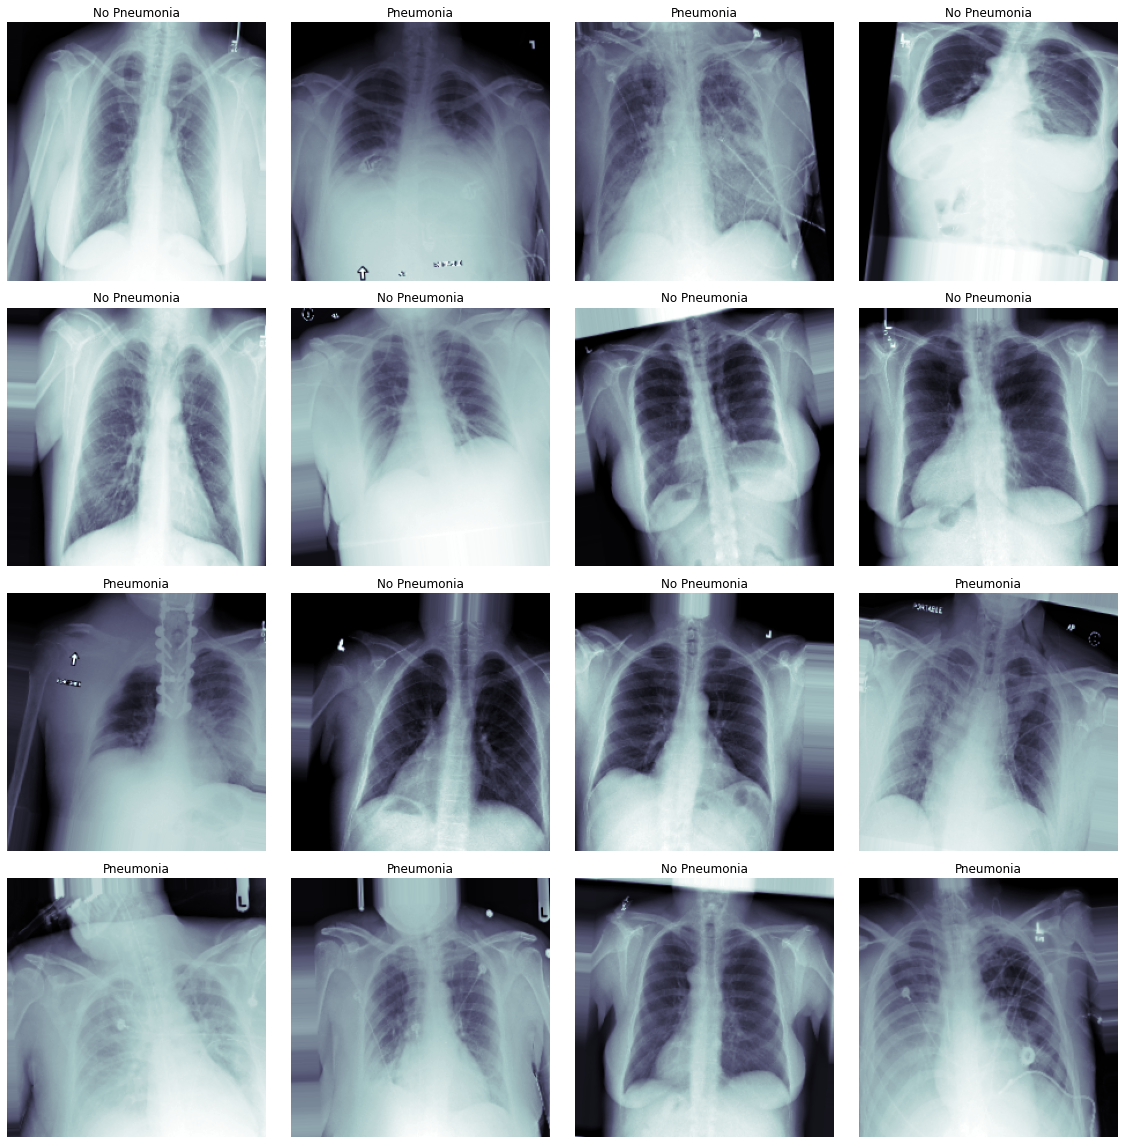

In [9]:
## Visualize augmented training samples
t_x, t_y = next(train_gen)
fig, m_axs = plt.subplots(4, 4, figsize=(16, 16))
for (c_x, c_y, c_ax) in zip(t_x, t_y, m_axs.flatten()):
    c_ax.imshow(c_x[:,:,0], cmap='bone')
    title = 'Pneumonia' if c_y == 1 else 'No Pneumonia'
    c_ax.set_title(title)
    c_ax.axis('off')
plt.tight_layout()
plt.show()

## Build the model (VGG16 transfer learning)

In [17]:
def load_pretrained_model():
    base_model = VGG16(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
    # Freeze all layers except the last convolutional block
    for layer in base_model.layers[:-4]:
        layer.trainable = False
    for layer in base_model.layers[-4:]:
        layer.trainable = True
    return base_model

vgg_model = load_pretrained_model()
print('Base model loaded. Trainable layers:')
for layer in vgg_model.layers:
    if layer.trainable:
        print(' ', layer.name)

Base model loaded. Trainable layers:
  block5_conv1
  block5_conv2
  block5_conv3
  block5_pool


In [18]:
def build_my_model(base_model, learning_rate=1e-4):
    model = Sequential([
        base_model,
        Flatten(),
        Dense(1024, activation='relu'),
        Dropout(0.5),
        Dense(512, activation='relu'),
        Dropout(0.5),
        Dense(256, activation='relu'),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    optimizer = Adam(learning_rate=learning_rate)
    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['binary_accuracy']
    )
    return model

# Config A: baseline
my_model_A = build_my_model(vgg_model, learning_rate=1e-4)

# Config B: lower LR
my_model_B = build_my_model(vgg_model, learning_rate=1e-5)

# Config C: same LR, more epochs
my_model_C = build_my_model(vgg_model, learning_rate=1e-4)

In [12]:
def get_callbacks(config_name):
    weight_path = f'{config_name}_best.hdf5'
    checkpoint = ModelCheckpoint(
        weight_path,
        monitor='val_loss',
        verbose=1,
        save_best_only=True,
        mode='min',
        save_weights_only=True
    )
    early = EarlyStopping(
        monitor='val_loss',
        mode='min',
        patience=10,
        restore_best_weights=True
    )
    reduce_lr = ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-7
    )
    return [checkpoint, early, reduce_lr], weight_path

# Usage for each config
callbacks_A, path_A = get_callbacks('configA')
callbacks_B, path_B = get_callbacks('configB')
callbacks_C, path_C = get_callbacks('configC')

## Train the model

In [15]:
history_A = my_model_A.fit(
    train_gen,
    steps_per_epoch=max(1, len(train_df) // BATCH_SIZE),
    validation_data=val_gen,
    validation_steps=max(1, len(val_df) // BATCH_SIZE),
    epochs=20,
    callbacks=callbacks_A
)

Epoch 1/20
71/71 [==============================] - 75s 1s/step - loss: 0.7381 - binary_accuracy: 0.5169 - val_loss: 0.7002 - val_binary_accuracy: 0.2861

Epoch 00001: val_loss improved from inf to 0.70023, saving model to configA_best.hdf5
Epoch 2/20
71/71 [==============================] - 68s 961ms/step - loss: 0.6926 - binary_accuracy: 0.5236 - val_loss: 0.6848 - val_binary_accuracy: 0.6043

Epoch 00002: val_loss improved from 0.70023 to 0.68477, saving model to configA_best.hdf5
Epoch 3/20
71/71 [==============================] - 66s 927ms/step - loss: 0.6844 - binary_accuracy: 0.5602 - val_loss: 0.7250 - val_binary_accuracy: 0.6321

Epoch 00003: val_loss did not improve from 0.68477
Epoch 4/20
71/71 [==============================] - 66s 930ms/step - loss: 0.6771 - binary_accuracy: 0.5858 - val_loss: 0.7448 - val_binary_accuracy: 0.4917

Epoch 00004: val_loss did not improve from 0.68477
Epoch 5/20
71/71 [==============================] - 65s 914ms/step - loss: 0.6728 - binary_ac

In [17]:
my_model_A.load_weights('configA_best.hdf5')
val_gen.reset()
y_prob = my_model_A.predict(val_gen, steps=len(val_df) // BATCH_SIZE, verbose=1)
y_true = val_df['Pneumonia'].values[:len(y_prob)] 

from sklearn.metrics import roc_auc_score, f1_score
print(f"AUC: {roc_auc_score(y_true, y_prob):.3f}")
print(f"F1: {f1_score(y_true, (y_prob >= 0.5).astype(int)):.3f}")

45/45 [==============================] - 19s 419ms/step
AUC: 0.683
F1: 0.414


In [13]:
# Rebuilding with lower LR
my_model_B = build_my_model(vgg_model, learning_rate=1e-5)
callbacks_B, path_B = get_callbacks('configB')

history_B = my_model_B.fit(
    train_gen,
    steps_per_epoch=max(1, len(train_df) // BATCH_SIZE),
    validation_data=val_gen,
    validation_steps=max(1, len(val_df) // BATCH_SIZE),
    epochs=30,
    callbacks=callbacks_B
)

Epoch 1/30
71/71 [==============================] - 76s 1s/step - loss: 0.7645 - binary_accuracy: 0.5103 - val_loss: 0.8283 - val_binary_accuracy: 0.2014

Epoch 00001: val_loss improved from inf to 0.82834, saving model to configB_best.hdf5
Epoch 2/30
71/71 [==============================] - 70s 982ms/step - loss: 0.7266 - binary_accuracy: 0.5210 - val_loss: 0.7135 - val_binary_accuracy: 0.5181

Epoch 00002: val_loss improved from 0.82834 to 0.71349, saving model to configB_best.hdf5
Epoch 3/30
71/71 [==============================] - 68s 962ms/step - loss: 0.7063 - binary_accuracy: 0.5294 - val_loss: 0.7472 - val_binary_accuracy: 0.4513

Epoch 00003: val_loss did not improve from 0.71349
Epoch 4/30
71/71 [==============================] - 69s 967ms/step - loss: 0.7000 - binary_accuracy: 0.5397 - val_loss: 0.6706 - val_binary_accuracy: 0.5612

Epoch 00004: val_loss improved from 0.71349 to 0.67061, saving model to configB_best.hdf5
Epoch 5/30
71/71 [==============================] - 67

In [14]:
# Config C: more epochs, same LR
my_model_C = build_my_model(vgg_model, learning_rate=1e-4)
callbacks_C, path_C = get_callbacks('configC')

history_C = my_model_C.fit(
    train_gen,
    steps_per_epoch=max(1, len(train_df) // BATCH_SIZE),
    validation_data=val_gen,
    validation_steps=max(1, len(val_df) // BATCH_SIZE),
    epochs=40,
    callbacks=callbacks_C
)

Epoch 1/40
71/71 [==============================] - 67s 944ms/step - loss: 0.7131 - binary_accuracy: 0.5085 - val_loss: 0.7014 - val_binary_accuracy: 0.4062

Epoch 00001: val_loss improved from inf to 0.70140, saving model to configC_best.hdf5
Epoch 2/40
71/71 [==============================] - 69s 966ms/step - loss: 0.6875 - binary_accuracy: 0.5589 - val_loss: 0.6791 - val_binary_accuracy: 0.5981

Epoch 00002: val_loss improved from 0.70140 to 0.67910, saving model to configC_best.hdf5
Epoch 3/40
71/71 [==============================] - 70s 991ms/step - loss: 0.6765 - binary_accuracy: 0.5785 - val_loss: 0.6501 - val_binary_accuracy: 0.7448

Epoch 00003: val_loss improved from 0.67910 to 0.65012, saving model to configC_best.hdf5
Epoch 4/40
71/71 [==============================] - 67s 940ms/step - loss: 0.6576 - binary_accuracy: 0.6227 - val_loss: 0.5543 - val_binary_accuracy: 0.6732

Epoch 00004: val_loss improved from 0.65012 to 0.55426, saving model to configC_best.hdf5
Epoch 5/40
7

In [15]:
my_model_C.load_weights('configC_best.hdf5')
val_gen.reset()
y_prob = my_model_C.predict(val_gen, steps=len(val_df) // BATCH_SIZE, verbose=1)
y_true = val_df['Pneumonia'].values[:len(y_prob)]

from sklearn.metrics import roc_auc_score, f1_score
print(f"AUC: {roc_auc_score(y_true, y_prob):.3f}")
print(f"F1: {f1_score(y_true, (y_prob >= 0.5).astype(int)):.3f}")

45/45 [==============================] - 19s 432ms/step
AUC: 0.683
F1: 0.416


## Evaluate performance

In [22]:
def plot_auc(t_y, p_y):
    fpr, tpr, thresholds = roc_curve(t_y, p_y)
    roc_auc = auc(fpr, tpr)
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend(loc='lower right')
    plt.show()
    return roc_auc

def plot_pr_curve(t_y, p_y):
    precision, recall, thresholds = precision_recall_curve(t_y, p_y)
    plt.figure()
    plt.plot(recall, precision, color='blue', lw=2)
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.show()
    return precision, recall, thresholds

def plot_f1_vs_threshold(t_y, p_y):
    precision, recall, thresholds = precision_recall_curve(t_y, p_y)
    f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8)
    plt.figure()
    plt.plot(thresholds, f1_scores[:-1], color='green', lw=2)
    plt.xlabel('Threshold')
    plt.ylabel('F1 Score')
    plt.title('F1 Score vs. Threshold')
    plt.show()
    best_idx = np.argmax(f1_scores[:-1])
    best_threshold = thresholds[best_idx]
    best_f1 = f1_scores[best_idx]
    print(f'Best threshold: {best_threshold:.3f}, F1: {best_f1:.3f}')
    return best_threshold, best_f1

def plot_history(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(history.history['loss'], label='train loss')
    ax1.plot(history.history['val_loss'], label='val loss')
    ax1.set_title('Loss')
    ax1.set_xlabel('Epoch')
    ax1.legend()
    ax2.plot(history.history['binary_accuracy'], label='train acc')
    ax2.plot(history.history['val_binary_accuracy'], label='val acc')
    ax2.set_title('Binary Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.legend()
    plt.tight_layout()
    plt.show()

46/46 [==============================] - 20s 429ms/step


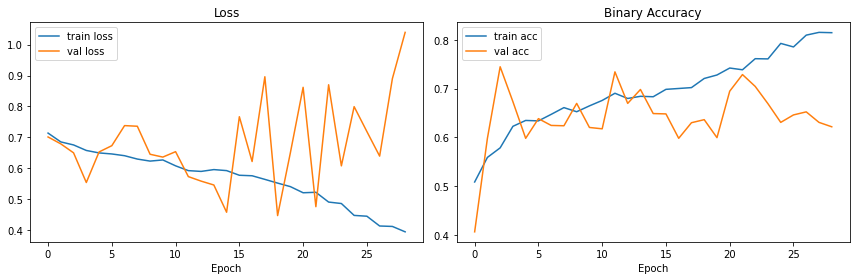

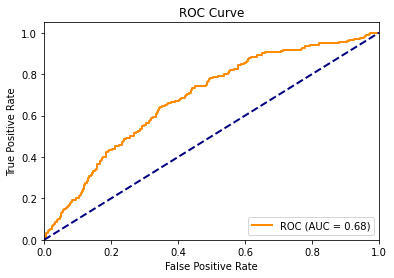

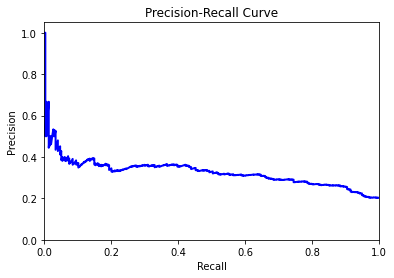

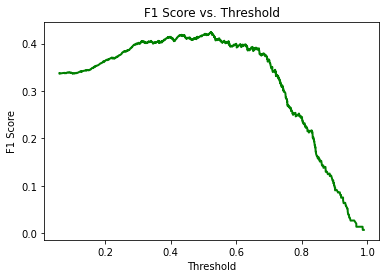

Best threshold: 0.523, F1: 0.424


In [24]:
## Plot all performance figures
my_model_C.load_weights('configC_best.hdf5')
val_gen.reset()
pred_Y = my_model_C.predict(val_gen, steps=len(val_df)//BATCH_SIZE + 1, verbose=1)
true_Y = val_gen.classes[:len(pred_Y)]

plot_history(history_C)
auc_score = plot_auc(true_Y, pred_Y.flatten())
precision, recall, thresholds = plot_pr_curve(true_Y, pred_Y.flatten())
best_thresh, best_f1 = plot_f1_vs_threshold(true_Y, pred_Y.flatten())

In [25]:
## Final threshold evaluation
THRESHOLD = best_thresh
print(f'Using threshold: {THRESHOLD:.3f}')
binary_preds = (pred_Y.flatten() >= THRESHOLD).astype(int)
print('Confusion Matrix:')
print(confusion_matrix(true_Y, binary_preds))
print(f'Accuracy: {accuracy_score(true_Y, binary_preds):.3f}')
print(f'F1: {f1_score(true_Y, binary_preds):.3f}')

Using threshold: 0.523
Confusion Matrix:
[[767 409]
 [105 189]]
Accuracy: 0.650
F1: 0.424


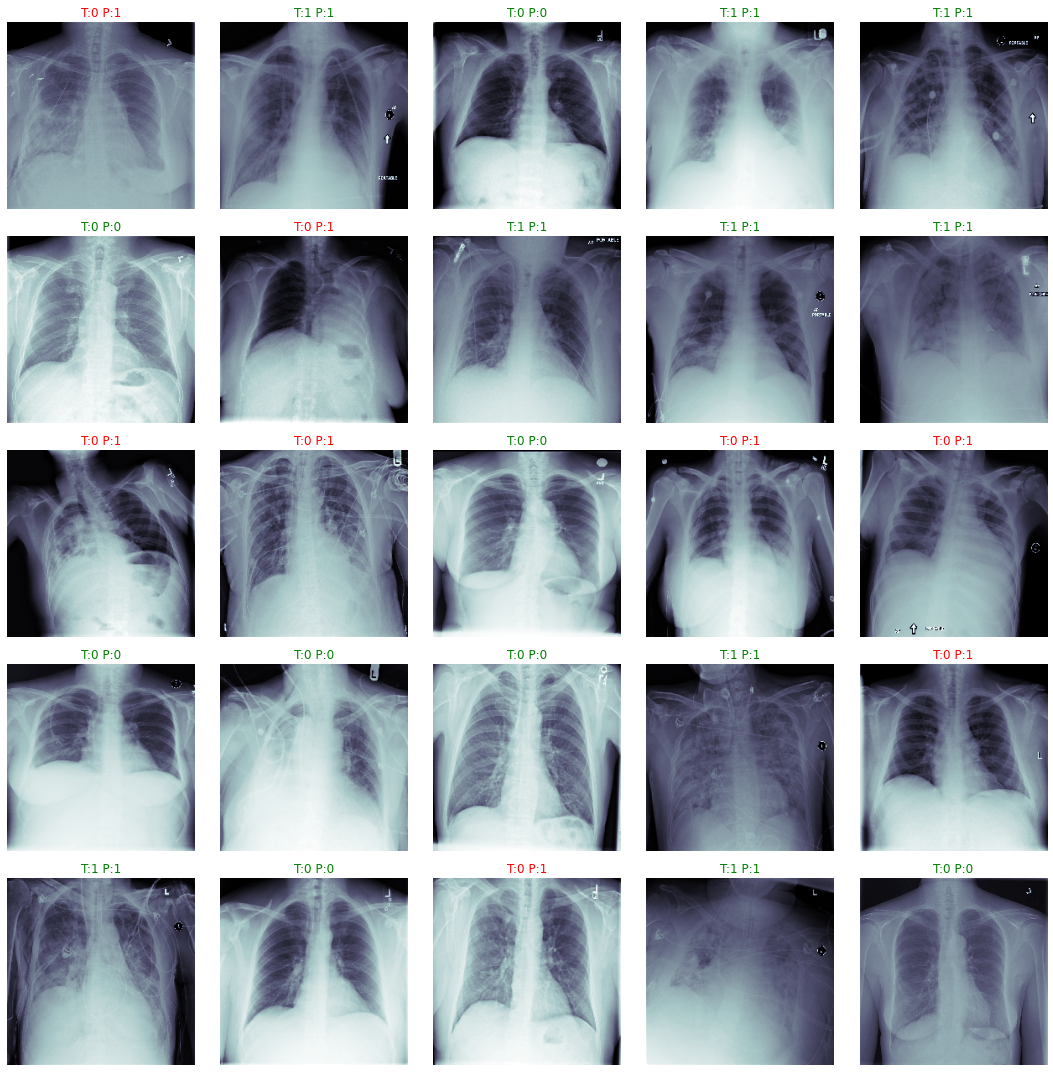

In [17]:
## Visualize true vs predicted examples
fig, m_axs = plt.subplots(5, 5, figsize=(15, 15))
i = 0
for (c_x, c_y, c_ax) in zip(valX[:25], true_Y[:25], m_axs.flatten()):
    c_ax.imshow(c_x[:,:,0], cmap='bone')
    pred_label = 1 if pred_Y[i] >= THRESHOLD else 0
    title = f'T:{int(c_y)} P:{pred_label}'
    color = 'green' if int(c_y) == pred_label else 'red'
    c_ax.set_title(title, color=color)
    c_ax.axis('off')
    i += 1
plt.tight_layout()
plt.show()

In [27]:
model_json = my_model_C.to_json()
with open('my_model.json', 'w') as json_file:
    json_file.write(model_json)

my_model_C.save_weights('my_model_weights.h5')
print('Model architecture saved to my_model.json')
print('Model weights saved to my_model_weights.h5')
print(f'Best threshold for FDA documentation: {THRESHOLD:.3f}')

Model architecture saved to my_model.json
Model weights saved to my_model_weights.h5
Best threshold for FDA documentation: 0.523
